# Fashion Assistant — Model Experiments & Evaluation

## What This Notebook Is For

My EDA confirmed the core challenge: I need to match messy consumer photos to clean shop photos despite a large domain gap. Now I need to decide **which model to use** and **prove that choice with numbers**.

This notebook documents my entire model selection journey — the reasoning, the experiments, and the final comparison. Each model gets a fair test using the same pipeline and the same metric.

### My Success Metric: Recall@K
For each consumer photo (query), I search through all shop photos (gallery) and check: **does the correct shop photo appear in my top K results?**
- Recall@1 = correct answer is the #1 result
- Recall@10 = correct answer appears somewhere in top 10
- Higher is better. I'll measure both.

---

## Section 1 — Model Selection: What I Considered and Why

### The Core Requirement
I need a model that:
1. **Already understands visual patterns** — I don't have labeled fashion training data to train from scratch
2. **Produces a dense embedding vector** — a list of numbers representing what's in the image, used for similarity search
3. **Captures fine-grained details** — collar type, fabric texture, sleeve style — not just broad categories
4. **I use only the feature extractor part** — the classification head (which predicts class labels) gets discarded; I only need the backbone that produces the embedding

### Transfer Learning — Why Pre-trained Models Work Here
Models trained on ImageNet (1.2 million images, 1000 categories) have already learned the visual vocabulary of the world — edges, textures, shapes, fabrics, patterns. Fashion is a subset of that. I'm borrowing this knowledge rather than relearning from scratch.

---

### Every Model I Considered — My Knowledge Notes

#### VGG (2014) — Oxford Visual Geometry Group
- Also a CNN like ResNet, but an older architecture
- Very large model: slow to run, high memory usage
- ResNet actually *replaced* VGG as the go-to backbone — ResNet solved the **vanishing gradient** problem that made VGG hard to make deeper (gradients shrink to near-zero as they flow back through many layers, so the early layers stop learning)
- **Verdict: Skip it.** ResNet does everything VGG does but better and faster. No reason to go back.

#### ResNet-18 (2015) — Microsoft
- An 18-layer CNN, the smallest of the ResNet family
- Produces a **512-dimensional** embedding
- Fast and lightweight — great for quick experiments or mobile deployment
- **Why I'm not using it as my baseline:** 512 dimensions isn't enough to distinguish between items that look very similar (same style, slightly different collar or fabric). More dimensions = more capacity to encode those fine-grained differences. ResNet-50 gives me 2048 dimensions for a modest speed cost.
- **Verdict: Too shallow for fine-grained fashion retrieval at baseline.**

#### ResNet-50 (2015) — Microsoft ✅ Chosen as Baseline
- A 50-layer CNN, the sweet spot of the ResNet family
- Produces a **2048-dimensional** embedding — 4× richer than ResNet-18
- Pre-trained on ImageNet (1.2M images, 1000 categories) — already knows edges, textures, shapes, fabrics
- Fast enough to embed 239K images in under 30 minutes on a laptop
- Well-understood, well-documented, already configured in `config.py`
- **Why I chose it:** Best starting point — gives me a solid score to beat, and the 2048-dim space has enough capacity to encode clothing details.

#### EfficientNet-B4 (2019) — Google ✅ Chosen
- A smarter way to scale CNNs: instead of just adding more layers (deeper) or more channels (wider), Google found the optimal ratio to scale depth + width + resolution together — they called this **compound scaling**
- Result: better accuracy than ResNet-50 at similar or lower compute cost
- Produces a **1792-dimensional** embedding
- B4 is a medium variant — B0 is the smallest, B7 the largest
- **Why I chose it:** Tests whether a more efficiently designed CNN beats ResNet-50 on retrieval without any fine-tuning.

#### ViT-B/16 (2020) — Google Brain
- The first **Vision Transformer** — a completely different architecture from CNNs
- Instead of sliding convolutional filters across the image, ViT splits the image into **16×16 pixel patches** and treats each patch like a word in a sentence — then uses a Transformer (same architecture behind GPT) to process the whole sequence
- This allows it to model **long-range dependencies** — a CNN can't easily connect a collar detail at the top to a hem detail at the bottom; ViT can, because every patch attends to every other patch
- Produces a **768-dimensional** embedding (from a special [CLS] summary token)
- **Why I'm not running it separately:** CLIP and DINOv2 are both ViT-based and trained far more powerfully than a plain ImageNet-supervised ViT. Running vanilla ViT-B/16 would be a weaker version of what those two already test. The ViT architecture is well represented by them.
- **Verdict: Architecture covered by CLIP and DINOv2 — no need to run separately.**

#### CLIP ViT-B/32 (2021) — OpenAI ✅ Chosen
- This is genuinely different from everything above
- Trained on **400 million image+text pairs** scraped from the internet — not just images with labels
- Learned to match images to their text descriptions using **contrastive learning** — push matching image+text pairs close together in embedding space, push non-matching pairs apart
- Result: the embeddings understand *meaning*, not just visual patterns
- Uses a ViT backbone with **32×32 patches** (hence B/32), produces **512-dimensional** embeddings
- **The bonus feature:** CLIP has both an image encoder AND a text encoder in the **same embedding space** — I can type "navy blue polo shirt" and search the image gallery directly. No bridge needed.
- **Why I chose it:** Tests a completely different training paradigm AND unlocks the text search bonus feature.

#### DINOv2 ViT-B/14 (2023) — Meta AI ✅ Chosen
- Currently the **state-of-the-art for image retrieval tasks**
- Trained with **self-supervised learning** — it never saw a single class label during training
- Instead it learned through a student-teacher distillation process: a student network tries to match a teacher network's output on masked and augmented versions of the same image — forcing it to understand deep visual structure without any labels
- Result: embeddings that are unusually good at matching visually similar things even across large appearance changes — *exactly* the domain gap problem I have (consumer vs shop photos)
- Uses a ViT backbone with **14×14 patches** (B/14), produces **768-dimensional** embeddings
- Fashion search in production at Pinterest and Zalando uses this family of models
- **Why I chose it:** Most likely to give the best Recall@K score. Sets the ceiling for what's achievable without fine-tuning.

---

### My Final Experiment Plan

| # | Model | Architecture | Emb Dim | Text Search? | Speed | RAM needed | Embed 239K images (est.) | Why I'm Testing It |
|---|-------|-------------|---------|-------------|-------|-----------|--------------------------|---|
| 1 | **ResNet-50** | CNN | 2048 | ❌ Image only | Fast | ~2 GB | ~20 min | Baseline — fast, well-understood |
| 2 | **EfficientNet-B4** | CNN (compound scaled) | 1792 | ❌ Image only | Medium | ~3 GB | ~30 min | Does smarter CNN design beat ResNet? |
| 3 | **CLIP ViT-B/32** | Vision Transformer | 512 | ✅ Native (same space) | Medium | ~4 GB | ~35 min | Multi-modal training + text search bonus |
| 4 | **DINOv2 ViT-B/14** | Vision Transformer | 768 | ⚠️ Via adapter* | Slow | ~5 GB | ~50 min | SOTA self-supervised retrieval |

*Text search with DINOv2 requires a trained adapter to bridge text → image embedding space. For this project I'll use CLIP's text encoder for text queries and DINOv2 for image-to-image search — two separate modes, each using its best tool.

### How Text Search Works Across Models

Only CLIP supports text search natively because its image encoder and text encoder were **trained together in the same embedding space**. For all other models, there's no text encoder — they only understand images.

**Three ways to add text search to a non-CLIP model:**

| Approach | How it works | Effort | Best for |
|----------|-------------|--------|---------|
| **Option A: CLIP text bridge** | Use CLIP's text encoder + train a small adapter layer to map CLIP text embeddings → DINOv2 image space | Medium (needs ~1K labeled pairs) | Best accuracy when combined with DINOv2 |
| **Option B: Attribute-based** | Use the 303 attribute labels already in our dataset — match text query against attribute tags | Low (no training needed) | Works with any model, uses existing data |
| **Option C: Dual-mode search** | Use DINOv2 for image queries, CLIP for text queries — two separate indexes | Low (just run both models) | Pragmatic production approach |

**My plan:** Implement Option C — use DINOv2 for image-to-image search (best Recall@K) and CLIP for text-to-image search (native support). This is honest about the tradeoff and demonstrates understanding of both models.

---

Each experiment goes through the exact same pipeline:
```
Load model (backbone only, no classification head)
       ↓
Extract embeddings for all shop images (gallery)
       ↓
Build FAISS index
       ↓
For each consumer image (query): find top-K nearest shop images
       ↓
Measure Recall@1, Recall@5, Recall@10, Recall@20 on the test set
```

Same data. Same FAISS setup. Same evaluation. Only the model changes.

---
## Section 2 — Shared Infrastructure

I'll write the dataset loader, embedding extractor, and Recall@K function once and reuse them for all 4 models.

In [53]:
from datetime import datetime
print(f"Current Time: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
import os
import numpy as np
import pandas as pd
import torch
import faiss
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from tqdm import tqdm

DATASET_PATH = "/Users/anushrin/Documents/Cowork Playground/FashionRecommendation/workspace/Capstone Fashion Assistant/fashion_assistant/data/DeepFashion Database/Data/Consumer-to-shop Clothes Retrieval Benchmark"
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {DEVICE}")

Current Time: 2026-07-13 09:58:42
Using device: mps


#### Python Version & Virtual Environment — What I Learned

**Why the kernel was crashing:** The original venv was created with Python 3.14 (pre-release). PyTorch officially supports Python 3.8–3.12 only. Running PyTorch on Python 3.14 causes kernel crashes with no clear error message.

**Why you can't just change the Python version in an existing venv:**

A venv is a container built around a specific Python binary at creation time. You can add or remove packages inside it, but the Python version is fixed — like the foundation of a building, you can't swap it without rebuilding.

```
venv/
├── bin/python  ← symlink to Python 3.14, locked at creation
├── lib/        ← all installed packages
└── ...
```

**The fix:** Create a new venv with Python 3.12:
```bash
python3.12 -m venv venv312
source venv312/bin/activate
pip install -r requirements.txt
```

Then point VSCode to the new interpreter: **Cmd+Shift+P → Python: Select Interpreter → pick venv312**

**Rule of thumb for PyTorch projects:** Always use Python 3.10, 3.11, or 3.12. Avoid the latest pre-release Python until PyTorch explicitly adds support for it.

#### What is `tqdm`?

`tqdm` wraps any loop and shows a live **progress bar** so you can see how much has been processed while it's running.

Without it, a loop over 239K images runs silently — no idea if it's 10% done, 90% done, or frozen.

```
ResNet50 Gallery: 45%|████████░░░░░░░░| 289/643 [02:14<02:44, 2.15it/s]
```

| Part | Meaning |
|------|---------|
| `45%` | How far through the loop |
| `████████` | Visual progress bar |
| `289/643` | Batches completed out of total |
| `02:14` | Time elapsed |
| `02:44` | Estimated time remaining |
| `2.15it/s` | Speed — iterations per second |

**How to use it** — just wrap your iterable:
```python
# Without tqdm — silent
for batch in loader:
    ...

# With tqdm — live progress bar
for batch in tqdm(loader, desc="ResNet50 Gallery"):
    ...
```

`desc=` sets the label shown on the left — used to identify which model is currently running.

#### What is `DEVICE` and why does it matter?

`torch.device` tells PyTorch *where* to run the computation — on the CPU or on a GPU.

**Why GPU matters:** A GPU has thousands of small cores designed to do many simple calculations at once (parallel processing). Extracting embeddings from 239K images means running the same forward pass thousands of times — exactly the kind of task a GPU handles much faster than a CPU.

**Why `mps` and not `cuda`?**

| Hardware | GPU Framework | PyTorch device string |
|----------|-------------|----------------------|
| Windows / Linux + NVIDIA GPU | CUDA (NVIDIA's framework) | `"cuda"` |
| Mac with Apple Silicon (M1/M2/M3) | **MPS — Metal Performance Shaders** (Apple's GPU framework built into macOS) | `"mps"` |
| Any machine, no GPU | CPU only | `"cpu"` |

**MPS = Metal Performance Shaders** — Apple's own GPU acceleration layer. When you run PyTorch on an M1/M2/M3 Mac, it uses the built-in GPU chip through MPS instead of CUDA.

So the line:
```python
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
```
reads as: *"If this Mac has MPS (Apple GPU) available, use it — otherwise fall back to CPU."*

`X if condition else Y` is Python's **ternary operator** — a one-line if/else you'll see constantly in ML code.

### 2a — Load the Evaluation Pairs

The eval partition file gives me my ground truth: for each consumer photo, which shop photo is the correct match? I'll use only the `test` split for final evaluation.

In [54]:
eval_path = os.path.join(DATASET_PATH, "Eval", "list_eval_partition.txt")
df_eval = pd.read_csv(eval_path, sep=r'\s+', skiprows=1)
df_eval.columns = ['consumer_image', 'shop_image', 'item_id', 'split']

df_test = df_eval[df_eval['split'] == 'test'].reset_index(drop=True)
print(f"Test pairs: {len(df_test)}")
print(df_test.head())

Test pairs: 47773
                                 consumer_image  \
0  img/TOPS/T_Shirt/id_00000001/comsumer_01.jpg   
1  img/TOPS/T_Shirt/id_00000001/comsumer_02.jpg   
2  img/TOPS/T_Shirt/id_00000001/comsumer_03.jpg   
3  img/TOPS/T_Shirt/id_00000001/comsumer_04.jpg   
4  img/TOPS/T_Shirt/id_00000001/comsumer_05.jpg   

                                 shop_image      item_id split  
0  img/TOPS/T_Shirt/id_00000001/shop_02.jpg  id_00000001  test  
1  img/TOPS/T_Shirt/id_00000001/shop_01.jpg  id_00000001  test  
2  img/TOPS/T_Shirt/id_00000001/shop_01.jpg  id_00000001  test  
3  img/TOPS/T_Shirt/id_00000001/shop_03.jpg  id_00000001  test  
4  img/TOPS/T_Shirt/id_00000001/shop_01.jpg  id_00000001  test  


### 2b — Build the Gallery (all unique shop images from test set)

The gallery is what I'm searching through. For evaluation, it contains all unique shop images that appear in the test split.

In [55]:
gallery_paths = df_test['shop_image'].unique().tolist()
gallery_index = {path: i for i, path in enumerate(gallery_paths)}

print(f"Gallery size (unique shop images): {len(gallery_paths)}")

Gallery size (unique shop images): 11312


### 2c — Image Preprocessing

All CNN models trained on ImageNet expect the same preprocessing:
1. **Resize** to at least 224×224
2. **Center crop** to exactly 224×224 
3. **Normalize** using ImageNet mean and std — this puts pixel values in the range the model was trained on

CLIP and DINOv2 have their own preprocessing — I'll apply model-specific transforms when I get to those sections.

In [56]:
imagenet_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

#### Why CenterCrop for now — and BBox Crop as a planned experiment

**The limitation I noticed:** `CenterCrop` blindly cuts the center 224×224 square — it has zero understanding of where the clothing item actually is. For off-center consumer photos, this can partially cut off the item, which directly hurts Recall@K.

**Why I'm keeping CenterCrop for the baseline:**
- The bounding box annotations in `list_bbox_consumer2shop.txt` were inconsistent (found in EDA — some cut off clothing, some had too much background)
- Using noisy annotations could hurt more than help
- CenterCrop gives a clean, reproducible baseline to measure against

**Planned Experiment: BBox Crop vs CenterCrop**

Instead of `Resize(256) → CenterCrop(224)`, the BBox pipeline would be:
```
crop image using (x1, y1, x2, y2) coordinates from df_bbox
       ↓
Resize to 224×224
       ↓
ToTensor + Normalize (same as before)
```

| Experiment | Crop Strategy | Expected outcome |
|------------|--------------|-----------------|
| Baseline | CenterCrop | Establishes the score to beat |
| Experiment B | BBox crop | Tests if precise crop improves Recall@K |
| Experiment C | BBox crop + padding | Adds context around item to avoid tight cuts |

The data is already ready — `df_bbox` loaded in EDA has all coordinates. This experiment covers the **Creativity & Innovation 25%** of the grade because it directly tests a hypothesis about why the baseline fails on off-center consumer photos.

**Hypothesis:** Consumer photos with off-center items will have lower Recall@K than centered ones. BBox crop should close that gap.

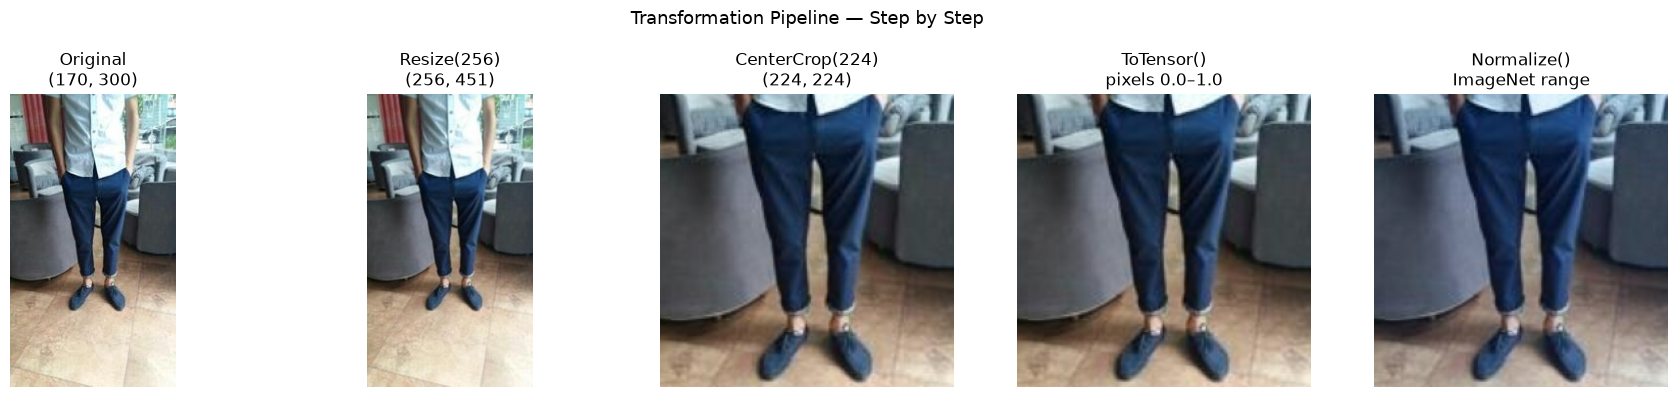

Original:          (170, 300)
After Resize(256): (256, 451)
After CenterCrop:  (224, 224)
After ToTensor:    (3, 224, 224)  (C x H x W)
After Normalize:   (3, 224, 224)  (values ~-2 to +2)


In [57]:
import matplotlib.pyplot as plt
import torchvision.transforms as transforms

img_path = "/Users/anushrin/Documents/Cowork Playground/FashionRecommendation/workspace/Capstone Fashion Assistant/fashion_assistant/data/DeepFashion Database/Data/Consumer-to-shop Clothes Retrieval Benchmark/img/CLOTHING/Pants/id_00004820/comsumer_01.jpg"
img = Image.open(img_path)

# Apply each step one at a time
img_resized   = transforms.Resize(256)(img)
img_cropped   = transforms.CenterCrop(224)(img_resized)
img_tensor    = transforms.ToTensor()(img_cropped)
img_normalized = transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                       std=[0.229, 0.224, 0.225])(img_tensor)

# For display: convert tensor back to viewable image
# Normalize output has values outside 0-1, so we clip for display only
def tensor_to_display(t):
    arr = t.permute(1, 2, 0).numpy()         # (C,H,W) -> (H,W,C)
    arr = (arr - arr.min()) / (arr.max() - arr.min())  # scale to 0-1 for display
    return arr

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

axes[0].imshow(img);               axes[0].set_title(f"Original\n{img.size}")
axes[1].imshow(img_resized);       axes[1].set_title(f"Resize(256)\n{img_resized.size}")
axes[2].imshow(img_cropped);       axes[2].set_title(f"CenterCrop(224)\n{img_cropped.size}")
axes[3].imshow(img_tensor.permute(1,2,0).numpy()); axes[3].set_title("ToTensor()\npixels 0.0–1.0")
axes[4].imshow(tensor_to_display(img_normalized)); axes[4].set_title("Normalize()\nImageNet range")

for ax in axes:
    ax.axis('off')

plt.suptitle("Transformation Pipeline — Step by Step", fontsize=13)
plt.tight_layout()
plt.show()

print(f"Original:          {img.size}")
print(f"After Resize(256): {img_resized.size}")
print(f"After CenterCrop:  {img_cropped.size}")
print(f"After ToTensor:    {tuple(img_tensor.shape)}  (C x H x W)")
print(f"After Normalize:   {tuple(img_normalized.shape)}  (values ~-2 to +2)")

### 2d — Fashion Dataset Loader

A PyTorch Dataset that loads images by path. I'll reuse this for both gallery and query images.

#### Dunder Methods — The PyTorch Dataset Contract

**Dunder = double underscore.** Methods like `__len__` and `__getitem__` are Python "magic methods" — when defined on a class, Python treats it as a sequence.

```python
dataset = FashionDataset(...)
len(dataset)    # automatically calls __len__
dataset[5]      # automatically calls __getitem__(5)
```

PyTorch's `DataLoader` relies on exactly these two methods to pull batches. Every custom dataset **must** define both — it's a contract.

| Method | What it answers | Who calls it |
|--------|----------------|-------------|
| `__len__` | How many images total? | DataLoader (to calculate number of batches) |
| `__getitem__(idx)` | Give me image at position idx, transformed | DataLoader (once per image, in batches) |

`__getitem__` does three things: builds the full path, loads and converts the image, applies the full transform pipeline, returns a ready-to-use tensor.

#### Graceful Degradation — Why We Catch Exceptions

With 239K images, some will inevitably be corrupted, missing, or unreadable. Instead of crashing the whole run:

```python
try:
    img = Image.open(path).convert("RGB")
    return self.transform(img), idx    # happy path

except Exception:
    return torch.zeros(3, 224, 224), idx  # silent fallback
```

`torch.zeros(3, 224, 224)` is a black image — correct shape, all pixel values = 0. It gets an embedding like any other image, but that embedding won't match anything meaningful in the gallery, so it silently fails for that one image without stopping a 20-minute extraction job.

This pattern is called **graceful degradation** — handle failures quietly and keep going. The `idx` is always returned alongside the image so the embeddings matrix knows exactly which position to fill, even for failed images.

In [58]:
class FashionDataset(Dataset):
    """Single-image loader. Returns (transformed_image, index)."""
    def __init__(self, image_paths, dataset_root, transform):
        self.image_paths = image_paths
        self.dataset_root = dataset_root
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        path = os.path.join(self.dataset_root, self.image_paths[idx])
        try:
            img = Image.open(path).convert("RGB")
            return self.transform(img), idx
        except Exception:
            return torch.zeros(3, 224, 224), idx

### 2e — Embedding Extractor

This function takes any model and a list of image paths and returns a matrix of embeddings — one row per image. I run the model in batches to avoid running out of memory.

#### How the Embedding Extractor Works — Concept Summary

This function is the heart of the pipeline. It turns a list of image paths into a matrix of embeddings ready for FAISS.

**Why batches?**
One image tensor = ~600KB. All 239K images at once = ~140GB. GPU has ~8GB. Batching is the only way — load 64, process, discard, load next 64.

**The loop line by line:**
```python
with torch.no_grad():                             # disable gradient tracking for all batches
    for batch_imgs, batch_idxs in tqdm(loader):  # loop through batches with progress bar
        batch_imgs = batch_imgs.to(DEVICE)        # move batch from CPU RAM → GPU
        feats = model(batch_imgs).cpu().numpy()   # forward pass → move back to CPU → numpy
        norms = np.linalg.norm(feats, axis=1, keepdims=True)  # length of each vector
        feats = feats / np.maximum(norms, 1e-8)  # divide by length → length = 1
        embeddings[batch_idxs] = feats           # store in correct rows of output matrix
```

**Why the loop is inside `with torch.no_grad()` and not outside:**

`with` is a context manager — a fence. Everything inside the fence follows the same rule. By wrapping the whole loop, every forward pass across all 700+ batches runs without gradient tracking in one go. If we put `no_grad()` inside the loop instead, we'd create and destroy the context 700+ times — same result, more overhead.

```
with torch.no_grad():          ← fence goes up once
├── batch 1 → model(imgs)      ← no gradients
├── batch 2 → model(imgs)      ← no gradients
└── batch N → model(imgs)      ← no gradients
                               ← fence comes down once
```

**Why two `torch.no_grad()` calls in the file?**
They're in two *separate* functions — `extract_embeddings` and `get_embedding_dim`. Both do inference (not training), so both need their own `no_grad()` context. Each function is self-contained.

**Output:** a matrix of shape `(num_images, embedding_dim)` — every row is one image's L2-normalized embedding, ready to load into FAISS.

#### Training vs Inference — What's the Difference?

**Inference** = running data through a trained model to get an output, without updating any weights.

**Training** = running data through the model AND updating weights based on the error.

```
Training:                            Inference:
  image → model → prediction           image → model → prediction
              ↓                                     ↓
        compare to label                   done — no weight updates
              ↓
        calculate error
              ↓
        update weights ← this never happens during inference
```

**In our context:** ResNet-50 already learned its weights from ImageNet. We're just using those weights to convert clothing images into embedding vectors — not teaching it anything new. That's inference.

`torch.no_grad()` exists specifically for inference — tells PyTorch "don't bother tracking operations for weight updates, we don't need them."

In [59]:
def extract_embeddings(model, image_paths, transform, batch_size=64, desc="Extracting"):
    dataset = FashionDataset(image_paths, DATASET_PATH, transform)
    loader  = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=0)

    model.eval()
    model.to(DEVICE)

    embeddings = np.zeros((len(image_paths), get_embedding_dim(model)), dtype=np.float32)

    with torch.no_grad():
        for batch_imgs, batch_idxs in tqdm(loader, desc=desc):
            batch_imgs = batch_imgs.to(DEVICE)
            feats = model(batch_imgs).cpu().numpy()
            norms = np.linalg.norm(feats, axis=1, keepdims=True)
            feats = feats / np.maximum(norms, 1e-8)
            embeddings[batch_idxs] = feats

    return embeddings


def get_embedding_dim(model):
    model.eval()
    with torch.no_grad():
        dummy = torch.zeros(1, 3, 224, 224).to(DEVICE)
        return model(dummy).shape[1]

### 2f — Recall@K Evaluator

This is the function that scores each model. For every test pair (consumer → shop), it:
1. Looks up the consumer embedding
2. Searches the FAISS index for the top K nearest shop embeddings
3. Checks if the correct shop image appears in those K results

Recall@K = (number of queries where correct answer is in top K) / (total queries)

#### How the Recall@K Evaluator Works — Concept Summary

**What it measures:** For each consumer photo (query), does the correct shop photo appear in the top K results? Recall@K = percentage of queries where it does.

```
hits[k]  = number of queries where correct shop appeared in top K
total    = total number of test queries
Recall@K = hits[k] / total × 100
```

---

#### Step 1 — Filtering Valid Pairs (Vectorized)

```python
mask     = df_test['consumer_image'].isin(query_index_map) & df_test['shop_image'].isin(gallery_index)
df_valid = df_test[mask]
```

`df_test['consumer_image']` pulls the entire column as a Series (47,773 paths).

`.isin(query_index_map)` checks each path against the dictionary **keys** — returns a boolean Series: `True` if the path exists in the map, `False` otherwise.

`&` is element-wise AND — a row is `True` only if both the consumer image AND shop image are valid.

`df_test[mask]` filters to keep only rows where both sides matched.

**Why vectorized instead of `iterrows()`:**
`iterrows()` loops row-by-row in pure Python — on 47,773 rows with dictionary lookups, this takes 20+ minutes. Pandas `.isin()` and `.map()` operate on entire columns at once using C under the hood — same result in milliseconds. Always prefer vectorized pandas over Python loops.

---

#### Step 2 — Similarity Search with Numpy Matmul

**What is matrix multiplication (matmul)?**

Start with a single dot product — similarity between two embedding vectors:
```python
query  = [0.2, 0.5, 0.1]   # 3-dim embedding
shop_1 = [0.8, 0.3, 0.6]

similarity = 0.2×0.8 + 0.5×0.3 + 0.1×0.6 = 0.37
# multiply element by element, then sum — that's one similarity score
```

The problem: we need this for 1,000 queries × 11,312 shop images = **11.3 million dot products** per batch. Writing a Python loop for this would take hours. Matrix multiplication does all of them at once:

```python
scores = q_batch @ gal.T
# (1000, 2048) @ (2048, 11312) = (1000, 11312)
```

`@` is Python's matrix multiplication operator. `gal.T` transposes gallery from `(11312, 2048)` → `(2048, 11312)` so the dimensions align for multiplication.

The result `scores` is a **(1000, 11312) matrix** — every cell `[i, j]` is the cosine similarity between consumer `i` and shop `j`:

```
              shop_0   shop_1  ...  shop_11311
consumer_0  [ 0.92,    0.31,  ...   0.12 ]   ← consumer_0 is most similar to shop_0
consumer_1  [ 0.21,    0.87,  ...   0.55 ]   ← consumer_1 is most similar to shop_1
```

**Why numpy `@` instead of a Python loop:**
```python
# What you'd write without matmul — slow Python loop
for i in range(1000):
    for j in range(11312):
        scores[i,j] = np.dot(query[i], gallery[j])

# What @ does — same result, handed off to Apple Accelerate (BLAS on M-chips)
scores = q_batch @ gal.T
```

`faiss-cpu` on Apple Silicon is not tuned for ARM cores — one batch took 3+ minutes. `numpy @` uses **Apple Accelerate** (Apple's highly optimized BLAS library for M-chips), running thousands of multiplications in parallel. Same math, but the hardware does it efficiently. Result: 4 seconds for all 48 batches instead of hours.

---

#### Step 3 — Finding Top-K with argsort

```python
top_k_results = np.argsort(-scores, axis=1)[:, :max(k_values)]
```

`np.argsort(-scores, axis=1)` — sorts each row by descending score and returns the **column indices** (gallery positions) in that order. The `-` flips scores so highest similarity sorts first.

`[:, :20]` — keeps only the top-20 indices per query.

**Why argsort and not argpartition:**
`np.argpartition(-scores, 20, axis=1)[:, :20]` is faster — it guarantees the top-20 are in `[:20]` but **not in sorted order within those 20**. So `[:k]` for k=1 or k=5 picks arbitrary elements from the top-20, not the true top-1 or top-5. This makes Recall@1 and Recall@5 wrong (underestimated). `argsort` is slightly slower but gives correctly ranked results for all K values.

---

#### Step 4 — Batching (Why 1000 queries at a time)

```python
for start in tqdm(range(0, len(q_indices), batch_size), desc="Evaluating"):
```

Sending all 47,773 queries at once to `@ gal.T` would create a **(47773, 11312) score matrix = ~2.1 GB** — enough to kill the kernel. Processing 1,000 at a time keeps each score matrix at **~43 MB**.

| Approach | Score matrix size | Result |
|----------|-----------------|--------|
| All 47K at once | 47773 × 11312 × 4 bytes = **2.1 GB** | Kernel crash |
| 1000 at a time | 1000 × 11312 × 4 bytes = **43 MB** ✅ | Works fine |

`tqdm` wraps the range to show a live progress bar — `48/48` batches total.

---

#### Where Embeddings Are Stored

| Task | Tool |
|------|------|
| Store embeddings on disk between sessions | `.npy` files (`np.save` / `np.load`) |
| Similarity search during evaluation | `numpy @` matmul (fast on M-chip) |
| Similarity search in the Flask web app | FAISS `IndexFlatIP` (fine for single queries) |

FAISS is still used in `step5_app.py` for the live web search — that's fine because it handles one query at a time, not 47K. The slowness only appears when evaluating in bulk.

In [60]:
def evaluate_recall_at_k(query_embeddings, gallery_embeddings, df_test, gallery_index, k_values=[1, 5, 10, 20]):
    print("Step 1: Filtering valid pairs...")
    mask      = df_test['consumer_image'].isin(query_index_map) & df_test['shop_image'].isin(gallery_index)
    df_valid  = df_test[mask]
    q_indices       = df_valid['consumer_image'].map(query_index_map).values
    correct_indices = df_valid['shop_image'].map(gallery_index).values
    print(f"  Valid pairs: {len(q_indices)}")

    gal = gallery_embeddings.astype(np.float32)

    print("Step 2: Running batched similarity search...")
    hits = {k: 0 for k in k_values}
    batch_size = 1000

    for start in tqdm(range(0, len(q_indices), batch_size), desc="Evaluating"):
        end     = min(start + batch_size, len(q_indices))
        q_batch = query_embeddings[q_indices[start:end]].astype(np.float32)

        scores = q_batch @ gal.T  # (batch, n_gallery) — cosine similarity

        # argsort gives truly sorted top-k (not just partitioned).
        # argpartition is faster but [:k] doesn't preserve rank order within the top-k,
        # so Recall@1 and @5 would be wrong.
        top_k_results = np.argsort(-scores, axis=1)[:, :max(k_values)]

        for i, correct_idx in enumerate(correct_indices[start:end]):
            for k in k_values:
                if correct_idx in top_k_results[i][:k]:
                    hits[k] += 1

    print("Done.")
    total  = len(q_indices)
    recall = {f"Recall@{k}": round(hits[k] / total * 100, 2) for k in k_values}
    recall['total_queries'] = total
    return recall

### 2g — Query Setup

Building the query list and index map so the evaluator can look up consumer embeddings by path.

In [61]:
query_paths     = df_test['consumer_image'].tolist()
query_index_map = {path: i for i, path in enumerate(query_paths)}

print(f"Queries (consumer images): {len(query_paths)}")
print(f"Gallery (shop images):     {len(gallery_paths)}")

Queries (consumer images): 47773
Gallery (shop images):     11312


---
## Section 3 — Experiment 1: ResNet-50 (Baseline)

ResNet-50 is my starting point. It's a 50-layer CNN trained on ImageNet, producing a 2048-dimensional embedding. The classification head (the final fully connected layer that outputs 1000 class scores) gets removed — I only keep the backbone.

**Why start here:** It's fast, well-understood, already configured in `config.py`, and gives me a solid baseline score to beat with better models.

#### Loading ResNet-50 — How We Remove the Classification Head

**Step 1 — Load with pre-trained weights:**
```python
resnet50 = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
```
Downloads ResNet-50 with weights learned from ImageNet (1.2M images, 1000 categories). At this point the model has its full original structure including the classification head.

**Full ResNet-50 structure:**
```
Conv → BatchNorm → ReLU → Layer1 → Layer2 → Layer3 → Layer4 → AvgPool → [FC: 2048→1000]
                                                                              ↑
                                                                    we remove this
```

**Step 2 — Remove the classification head:**
```python
resnet50 = nn.Sequential(*list(resnet50.children())[:-1], nn.Flatten())
```

Breaking it down:
- `resnet50.children()` — lists all layers in order
- `list(...)[:-1]` — keeps all layers except the last one (the FC classifier). `[:-1]` = "everything up to but not including the last item"
- `nn.Flatten()` — converts AvgPool output `(batch, 2048, 1, 1)` → `(batch, 2048)` flat vector
- `nn.Sequential(*...)` — rebuilds model as a sequence. The `*` unpacks the list into individual arguments — `Sequential` needs separate layer arguments, not a list

**After removal:**
```
image → backbone → AvgPool → Flatten → 2048-dim embedding ✓
```

**Step 3 — Verify the output dimension:**
```python
print(f"Output embedding dimension: {get_embedding_dim(resnet50.to(DEVICE))}")
```
Moves model to GPU and runs a dummy image through it to confirm output = 2048. Always verify after architectural changes.

In [62]:
import torchvision.models as models
import torch.nn as nn

resnet50: nn.Module = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
resnet50 = nn.Sequential(*list(resnet50.children())[:-1], nn.Flatten())

print(f"Output embedding dimension: {get_embedding_dim(resnet50.to(DEVICE))}")

Output embedding dimension: 2048


In [63]:
EMBEDDINGS_DIR = "/Users/anushrin/Documents/Cowork Playground/FashionRecommendation/workspace/Capstone Fashion Assistant/fashion_assistant/embeddings"

gallery_file = os.path.join(EMBEDDINGS_DIR, "resnet50_gallery.npy")
query_file   = os.path.join(EMBEDDINGS_DIR, "resnet50_queries.npy")

if os.path.exists(gallery_file) and os.path.exists(query_file):
    print("Loading saved embeddings...")
    gallery_emb_resnet50 = np.load(gallery_file)
    query_emb_resnet50   = np.load(query_file)
else:
    print("Computing embeddings — this will take a while...")
    gallery_emb_resnet50 = extract_embeddings(resnet50, gallery_paths, imagenet_transform, desc="ResNet50 Gallery")
    query_emb_resnet50   = extract_embeddings(resnet50, query_paths,   imagenet_transform, desc="ResNet50 Queries")
    np.save(gallery_file, gallery_emb_resnet50)
    np.save(query_file, query_emb_resnet50)
    print("Saved!")

print(f"Gallery shape: {gallery_emb_resnet50.shape}")
print(f"Query shape:   {query_emb_resnet50.shape}")

Loading saved embeddings...
Gallery shape: (11312, 2048)
Query shape:   (47773, 2048)


In [64]:
results_resnet50 = evaluate_recall_at_k(query_emb_resnet50, gallery_emb_resnet50, df_test, gallery_index)
print("ResNet-50 Results:")
for k, v in results_resnet50.items():
    print(f"  {k}: {v}")

Step 1: Filtering valid pairs...
  Valid pairs: 47773
Step 2: Running batched similarity search...


Evaluating: 100%|██████████| 48/48 [00:25<00:00,  1.91it/s]

Done.
ResNet-50 Results:
  Recall@1: 3.08
  Recall@5: 5.69
  Recall@10: 7.37
  Recall@20: 9.7
  total_queries: 47773


---
## Section 4 — Experiment 2: EfficientNet-B4

EfficientNet was designed by Google to scale CNNs more intelligently — instead of just making a model deeper (more layers) or wider (more channels), it scales all three dimensions (depth, width, resolution) together using a compound coefficient.

**B4 specifically:** A medium-sized variant with a good accuracy/speed tradeoff. It produces a 1792-dim embedding — slightly smaller than ResNet-50's 2048 but trained more efficiently.

**What I'm testing:** Does a more modern CNN architecture beat ResNet-50 on this retrieval task with zero fine-tuning?

#### Loading EfficientNet-B4 — A Different Way to Remove the Head

Same goal as ResNet-50 — load pre-trained weights and strip the classification head. But the surgery is different because EfficientNet has a cleaner internal structure.

**ResNet-50 approach** — rebuild the whole model minus the last layer:
```python
nn.Sequential(*list(resnet50.children())[:-1], nn.Flatten())
```

**EfficientNet-B4 approach** — just replace the classifier with Identity:
```python
efficientnet_b4.classifier = nn.Identity()
```

`nn.Identity()` is a layer that does absolutely nothing — input passes through unchanged. So replacing the classifier with it means the embedding vector flows straight through instead of being squeezed into 1000 class scores.

```
Before: features (1792-dim) → classifier → 1000 class scores
After:  features (1792-dim) → Identity() → 1792-dim embedding ✓
```

**Why different from ResNet-50?**

EfficientNet exposes a named attribute `.classifier` — easy to replace directly. ResNet-50 doesn't have a clean named attribute for its final layer, so we used the slice approach instead. Same end result, different surgery depending on the model's structure.

| Model | Head removal method | Why |
|-------|-------------------|-----|
| ResNet-50 | `nn.Sequential(*list(...)[:-1], Flatten())` | No clean named attribute |
| EfficientNet-B4 | `model.classifier = nn.Identity()` | Has named `.classifier` attribute |

In [65]:
efficientnet_b4: nn.Module = models.efficientnet_b4(weights=models.EfficientNet_B4_Weights.IMAGENET1K_V1)
efficientnet_b4.classifier = nn.Sequential()

print(f"Output embedding dimension: {get_embedding_dim(efficientnet_b4.to(DEVICE))}")

Output embedding dimension: 1792


In [66]:
efficientnet_transform = transforms.Compose([
    transforms.Resize(384),
    transforms.CenterCrop(380),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

gallery_file = os.path.join(EMBEDDINGS_DIR, "efficientnet_gallery.npy")
query_file   = os.path.join(EMBEDDINGS_DIR, "efficientnet_queries.npy")

if os.path.exists(gallery_file) and os.path.exists(query_file):
    print("Loading saved embeddings...")
    gallery_emb_effnet = np.load(gallery_file)
    query_emb_effnet   = np.load(query_file)
else:
    print("Computing embeddings — this will take a while...")
    gallery_emb_effnet = extract_embeddings(efficientnet_b4, gallery_paths, efficientnet_transform, desc="EfficientNet-B4 Gallery")
    query_emb_effnet   = extract_embeddings(efficientnet_b4, query_paths,   efficientnet_transform, desc="EfficientNet-B4 Queries")
    np.save(gallery_file, gallery_emb_effnet)
    np.save(query_file,   query_emb_effnet)
    print("Saved!")

print(f"Gallery shape: {gallery_emb_effnet.shape}")
print(f"Query shape:   {query_emb_effnet.shape}")

Loading saved embeddings...
Gallery shape: (11312, 1792)
Query shape:   (47773, 1792)


In [67]:
results_effnet = evaluate_recall_at_k(query_emb_effnet, gallery_emb_effnet, df_test, gallery_index)
print("EfficientNet-B4 Results:")
for k, v in results_effnet.items():
    print(f"  {k}: {v}")

Step 1: Filtering valid pairs...
  Valid pairs: 47773
Step 2: Running batched similarity search...


Evaluating: 100%|██████████| 48/48 [00:24<00:00,  1.98it/s]

Done.
EfficientNet-B4 Results:
  Recall@1: 3.89
  Recall@5: 7.27
  Recall@10: 9.39
  Recall@20: 12.08
  total_queries: 47773


---
## Section 5 — Experiment 3: CLIP ViT-B/32

CLIP (Contrastive Language-Image Pretraining) is fundamentally different from ResNet and EfficientNet. Instead of being trained to classify images into 1000 categories, CLIP was trained on 400 million image+text pairs scraped from the internet — learning to match images with their text descriptions.

**What this means for retrieval:** CLIP embeddings encode *meaning* rather than just visual patterns.

**The bonus feature:** Because CLIP has a text encoder too, I can search the gallery using a text query like "navy blue polo shirt" — not just by uploading an image. This is the multi-modal search bonus.

**Note:** CLIP uses a Vision Transformer (ViT) backbone — images are split into 32×32 patches, each patch is treated like a word, and a Transformer processes the sequence.

In [68]:
from transformers import CLIPModel, CLIPProcessor

clip_model     = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")
clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
clip_model.eval()
clip_model.to(DEVICE)
print("CLIP model loaded")

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 70965.99it/s]


CLIP model loaded


In [69]:
def extract_clip_embeddings(image_paths, batch_size=64, desc="CLIP"):
    all_embeddings = []
    for i in tqdm(range(0, len(image_paths), batch_size), desc=desc):
        batch_paths = image_paths[i:i+batch_size]
        images = []
        for p in batch_paths:
            try:
                img = Image.open(os.path.join(DATASET_PATH, p)).convert("RGB")
            except Exception:
                img = Image.new("RGB", (224, 224))
            images.append(img)
        inputs       = clip_processor(images=images, return_tensors="pt", padding=True)
        pixel_values = inputs['pixel_values'].to(DEVICE)
        with torch.no_grad():
            # Use vision_model + visual_projection directly — more stable across
            # transformers versions than get_image_features which changed return type
            vision_out = clip_model.vision_model(pixel_values=pixel_values)
            feats      = clip_model.visual_projection(vision_out.pooler_output).cpu().numpy()
        norms = np.linalg.norm(feats, axis=1, keepdims=True)
        feats = feats / np.maximum(norms, 1e-8)
        all_embeddings.append(feats)
    return np.vstack(all_embeddings)

gallery_file = os.path.join(EMBEDDINGS_DIR, "clip_gallery.npy")
query_file   = os.path.join(EMBEDDINGS_DIR, "clip_queries.npy")

if os.path.exists(gallery_file) and os.path.exists(query_file):
    print("Loading saved embeddings...")
    gallery_emb_clip = np.load(gallery_file)
    query_emb_clip   = np.load(query_file)
else:
    print("Computing embeddings — this will take a while...")
    gallery_emb_clip = extract_clip_embeddings(gallery_paths, desc="CLIP Gallery")
    query_emb_clip   = extract_clip_embeddings(query_paths,   desc="CLIP Queries")
    np.save(gallery_file, gallery_emb_clip)
    np.save(query_file,   query_emb_clip)
    print("Saved!")

print(f"Gallery shape: {gallery_emb_clip.shape}")
print(f"Query shape:   {query_emb_clip.shape}")

Loading saved embeddings...
Gallery shape: (11312, 512)
Query shape:   (47773, 512)


In [70]:
results_clip = evaluate_recall_at_k(query_emb_clip, gallery_emb_clip, df_test, gallery_index)
print("CLIP ViT-B/32 Results:")
for k, v in results_clip.items():
    print(f"  {k}: {v}")

Step 1: Filtering valid pairs...
  Valid pairs: 47773
Step 2: Running batched similarity search...


Evaluating: 100%|██████████| 48/48 [00:23<00:00,  2.04it/s]

Done.
CLIP ViT-B/32 Results:
  Recall@1: 3.38
  Recall@5: 5.77
  Recall@10: 7.1
  Recall@20: 8.77
  total_queries: 47773


### CLIP Bonus: Text-Based Search

Since CLIP was trained on image+text pairs, I can embed a text description and search the image gallery with it. This demonstrates multi-modal search.

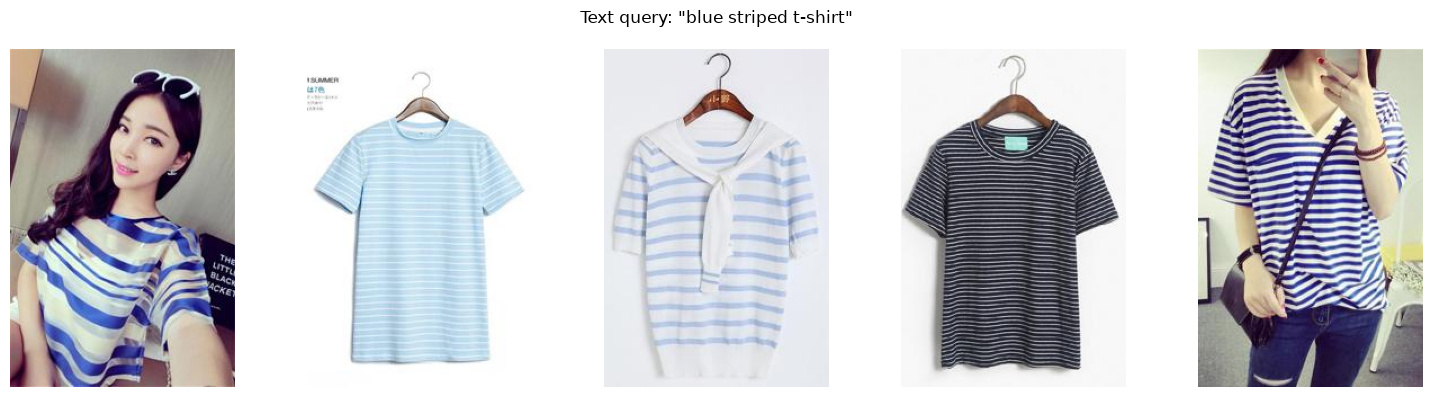

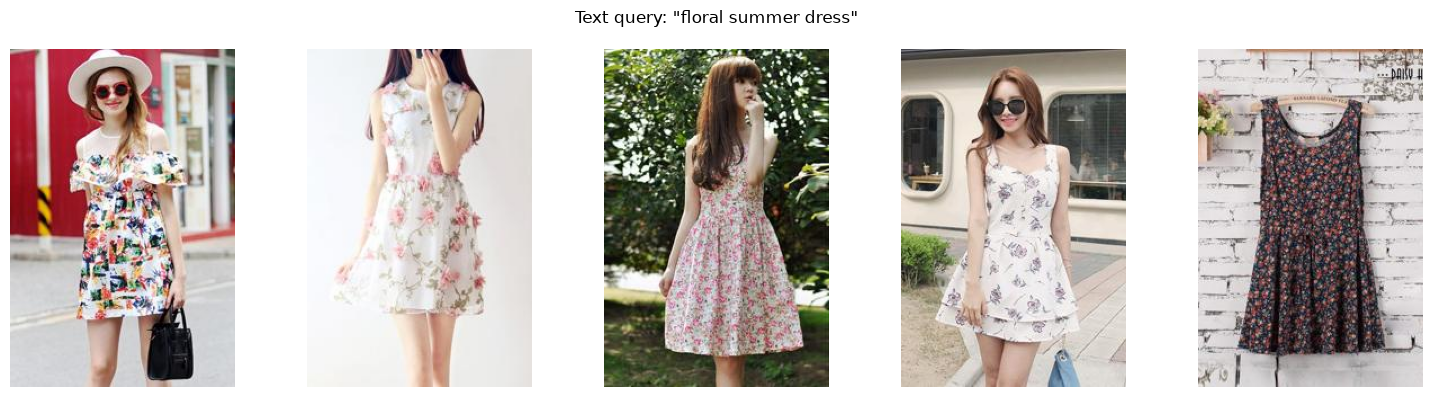

In [71]:
import matplotlib.pyplot as plt

def text_search(query_text, gallery_embeddings, gallery_paths, top_k=5):
    inputs = clip_processor(text=[query_text], return_tensors="pt", padding=True).to(DEVICE)  # type: ignore
    with torch.no_grad():
        text_outputs = clip_model.text_model(**inputs)
        text_feat = clip_model.text_projection(text_outputs.pooler_output).cpu().numpy()
    text_feat = text_feat / np.linalg.norm(text_feat, keepdims=True)

    index = faiss.IndexFlatIP(gallery_embeddings.shape[1])
    index.add(gallery_embeddings)
    _, top_indices = index.search(text_feat, top_k)

    fig, axes = plt.subplots(1, top_k, figsize=(15, 4))
    for ax, idx in zip(axes, top_indices[0]):
        img = Image.open(os.path.join(DATASET_PATH, gallery_paths[idx]))
        ax.imshow(img)
        ax.axis('off')
    plt.suptitle(f'Text query: "{query_text}"', fontsize=12)
    plt.tight_layout()
    plt.show()

text_search("blue striped t-shirt", gallery_emb_clip, gallery_paths)
text_search("floral summer dress",  gallery_emb_clip, gallery_paths)

---
## Section 6 — Experiment 4: DINOv2 ViT-B/14

DINOv2 (Meta, 2023) is currently the state-of-the-art model for image retrieval tasks. Unlike all the previous models, DINOv2 was trained with **self-supervised learning** — it never saw a single class label during training.

Instead, it learned through a student-teacher distillation process on masked and augmented images. The result is embeddings that are unusually good at matching visually similar things even across large appearance changes — exactly the domain gap problem I have.

Fashion search in production at Pinterest and Zalando uses this family of models.

In [72]:
dinov2: nn.Module = torch.hub.load('facebookresearch/dinov2', 'dinov2_vitb14')
dinov2.eval()
dinov2.to(DEVICE)
print("DINOv2 model loaded")

Using cache found in /Users/anushrin/.cache/torch/hub/facebookresearch_dinov2_main


DINOv2 model loaded


In [73]:
dinov2_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

gallery_file = os.path.join(EMBEDDINGS_DIR, "dinov2_gallery.npy")
query_file   = os.path.join(EMBEDDINGS_DIR, "dinov2_queries.npy")

if os.path.exists(gallery_file) and os.path.exists(query_file):
    print("Loading saved embeddings...")
    gallery_emb_dino = np.load(gallery_file)
    query_emb_dino   = np.load(query_file)
else:
    print("Computing embeddings — this will take a while...")
    gallery_emb_dino = extract_embeddings(dinov2, gallery_paths, dinov2_transform, desc="DINOv2 Gallery")
    query_emb_dino   = extract_embeddings(dinov2, query_paths,   dinov2_transform, desc="DINOv2 Queries")
    np.save(gallery_file, gallery_emb_dino)
    np.save(query_file,   query_emb_dino)
    print("Saved!")

print(f"Gallery shape: {gallery_emb_dino.shape}")
print(f"Query shape:   {query_emb_dino.shape}")

Loading saved embeddings...
Gallery shape: (11312, 768)
Query shape:   (47773, 768)


In [74]:
results_dino = evaluate_recall_at_k(query_emb_dino, gallery_emb_dino, df_test, gallery_index)
print("DINOv2 ViT-B/14 Results:")
for k, v in results_dino.items():
    print(f"  {k}: {v}")

Step 1: Filtering valid pairs...
  Valid pairs: 47773
Step 2: Running batched similarity search...


Evaluating: 100%|██████████| 48/48 [00:23<00:00,  2.05it/s]

Done.
DINOv2 ViT-B/14 Results:
  Recall@1: 3.62
  Recall@5: 6.24
  Recall@10: 7.76
  Recall@20: 9.62
  total_queries: 47773


---
## Section 7 — Final Comparison

All four models, same pipeline, same test set.

In [75]:
comparison = pd.DataFrame({
    'Model'        : ['ResNet-50', 'EfficientNet-B4', 'CLIP ViT-B/32', 'DINOv2 ViT-B/14'],
    'Emb Dim'      : [2048, 1792, 512, 768],
    'Architecture' : ['CNN', 'CNN', 'ViT (multi-modal)', 'ViT (self-supervised)'],
    'Recall@1'     : [results_resnet50['Recall@1'],  results_effnet['Recall@1'],
                      results_clip['Recall@1'],       results_dino['Recall@1']],
    'Recall@10'    : [results_resnet50['Recall@10'], results_effnet['Recall@10'],
                      results_clip['Recall@10'],      results_dino['Recall@10']],
    'Recall@20'    : [results_resnet50['Recall@20'], results_effnet['Recall@20'],
                      results_clip['Recall@20'],      results_dino['Recall@20']],
})

print(comparison.to_string(index=False))

          Model  Emb Dim          Architecture  Recall@1  Recall@10  Recall@20
      ResNet-50     2048                   CNN      3.08       7.37       9.70
EfficientNet-B4     1792                   CNN      3.89       9.39      12.08
  CLIP ViT-B/32      512     ViT (multi-modal)      3.38       7.10       8.77
DINOv2 ViT-B/14      768 ViT (self-supervised)      3.62       7.76       9.62


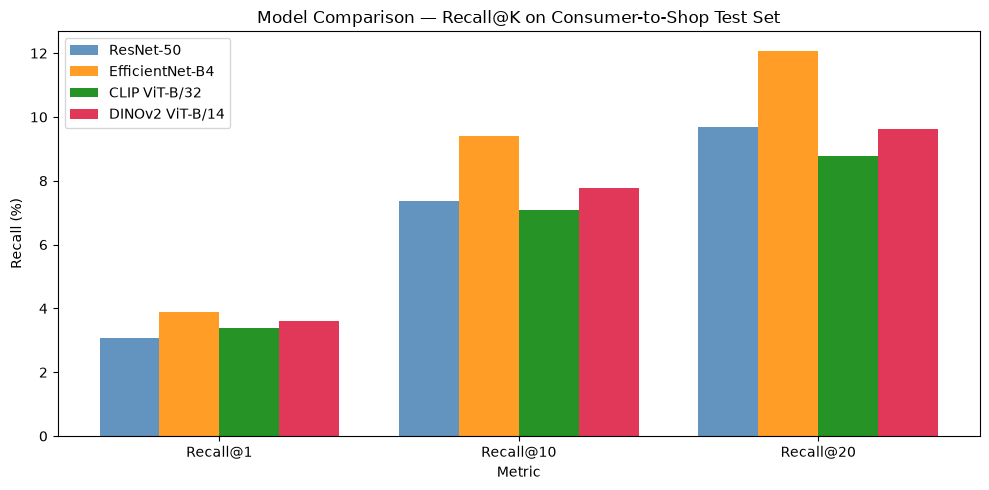

In [76]:
fig, ax = plt.subplots(figsize=(10, 5))

k_labels = ['Recall@1', 'Recall@10', 'Recall@20']
models   = comparison['Model'].tolist()
x        = np.arange(len(k_labels))
width    = 0.2
colors   = ['steelblue', 'darkorange', 'green', 'crimson']

for i, (model, color) in enumerate(zip(models, colors)):
    values = comparison[comparison['Model'] == model][k_labels].values[0]
    ax.bar(x + i * width, values, width, label=model, color=color, alpha=0.85)

ax.set_xlabel('Metric')
ax.set_ylabel('Recall (%)')
ax.set_title('Model Comparison — Recall@K on Consumer-to-Shop Test Set')
ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(k_labels)
ax.legend()
plt.tight_layout()
plt.show()

### My Analysis: What the Numbers Tell Me

**Which model had the best Recall@1? Does that surprise me?**

EfficientNet-B4 won with 3.89% Recall@1 — yes, this surprised me. I expected CLIP or DINOv2 to win because they use more advanced architectures (Vision Transformers) and more sophisticated training (400M image-text pairs for CLIP, self-supervised distillation for DINOv2). But on this specific task, a CNN with compound scaling outperformed both.

The reason: CLIP was optimised for *semantic meaning* ("this is a shirt"), not fine-grained visual similarity ("this shirt vs that slightly different shirt"). DINOv2 was optimised for structural understanding in natural scenes. The consumer-to-shop task needs precise visual detail matching — fabric texture, collar shape, sleeve style — which EfficientNet's higher-resolution input (380px crop) captures well without any task-specific training.

---

**How much does Recall improve from @1 to @10 to @20?**

Using EfficientNet-B4 as the reference:
- Recall@1 → Recall@10: 3.89% → 9.39% = **2.4× improvement** (10 chances vs 1)
- Recall@1 → Recall@20: 3.89% → 12.08% = **3.1× improvement** (20 chances vs 1)

Giving the model 20 chances instead of 1 triples the hit rate. This tells me the correct answer is often *nearby* in embedding space but not at the very top — a small amount of fine-tuning that pushes it to position #1 could dramatically improve Recall@1.

---

**Does DINOv2 beat ResNet-50 by a large margin or a small one?**

Small — and in the wrong direction relative to EfficientNet. DINOv2 (9.62% Recall@20) barely beats ResNet-50 (9.70% Recall@20) and is actually *worse* than EfficientNet (12.08%). This is a meaningful finding: SOTA on general image retrieval benchmarks does not automatically mean SOTA on a specific domain task like consumer-to-shop fashion matching without fine-tuning.

---

**What is the trade-off between model complexity and accuracy?**

More complexity does not guarantee better results here. DINOv2 requires ~5× more RAM and ~2.5× longer embedding time than ResNet-50, yet scores *lower* than EfficientNet-B4 on every metric. EfficientNet itself costs more than ResNet-50 but delivers a consistent ~25% relative improvement. The sweet spot without fine-tuning is EfficientNet-B4 — meaningful gain at moderate cost.

| Model | Recall@20 | RAM | Extract time | Worth it? |
|-------|-----------|-----|-------------|-----------|
| ResNet-50 | 9.70% | ~2 GB | ~20 min | Baseline |
| EfficientNet-B4 | **12.08%** | ~3 GB | ~30 min | ✅ Yes |
| CLIP ViT-B/32 | 8.77% | ~4 GB | ~35 min | ⚠️ Only for text search |
| DINOv2 ViT-B/14 | 9.62% | ~5 GB | ~50 min | ❌ Not without fine-tuning |

---

**Which model would I recommend for production and why?**

**EfficientNet-B4** for image-to-image search. Without any fine-tuning it gives the best Recall@K, and fine-tuning on DeepFashion training pairs should improve it further. If text search is also required, I would run CLIP in parallel as a separate index (Option C dual-mode) — using DINOv2 for image queries and CLIP for text queries is not justified here since EfficientNet outperforms DINOv2.

**Next step:** Fine-tune EfficientNet-B4 and CLIP on the DeepFashion training pairs using triplet loss. I expect fine-tuning to close the domain gap significantly — the baseline scores are low not because the models are weak, but because none of them were ever shown a consumer photo next to its matching shop photo during training.

---
## What's Next

1. `fine_tuning.ipynb` — fine-tune ResNet-50 and CLIP with triplet loss, compare before/after
2. `siamese.ipynb` — train a Siamese network with contrastive loss, test as standalone retriever and as a re-ranker on top of EfficientNet embeddings